# <center>**Xây dựng mô hình phân cụm K-means trên tập dữ liệu mua sắm tại siêu thị**<center>
## Mục tiêu: 
- Làm sạch dữ liệu giao dịch (xử lý missing, cancel, v.v.)
- Tính toán RFM (Recency, Frequency, Monetary) cho từng khách hàng
- Trực quan hóa phân phối RFM
- Chuẩn hóa dữ liệu RFM
- Tìm số cụm tối ưu bằng Elbow Method + Silhouette Score
- Huấn luyện K-means (K tối ưu)
- Trực quan hóa kết quả phân cụm (ví dụ: 3D scatter plot RFM)
- Phân tích và gợi ý chiến lược marketing cho từng cụm (ví dụ: VIP, At Risk, Lost, New)

**Lưu ý**: 
- Dataset từ Kaggle: https://www.kaggle.com/datasets/hellbuoy/online-retail-customer-clustering
- File chính: `Online_Retail.csv` (giao dịch từ 2010-2011, UK-based online retail)
- Chạy trên Jupyter Notebook. Tải file CSV về và đặt cùng thư mục với notebook.
- RFM là tiêu chuẩn cho customer segmentation: 
  - **Recency**: Ngày kể từ giao dịch cuối (thấp = tốt)
  - **Frequency**: Số lượng giao dịch (cao = tốt)
  - **Monetary**: Tổng chi tiêu (cao = tốt)

In [ ]:
# Import các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')
# Cài đặt style đẹp hơn
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
%matplotlib inline

# Đọc file
df = pd.read_csv('online_retail_clustering.csv', encoding='latin1')  
# hoặc encoding='ISO-8859-1', hoặc encoding='windows-1252' đều được

print("Shape ban đầu:", df.shape)
df.head()

Shape ban đầu: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


## **1. Khám phá dữ liệu**

In [27]:
# Thông tin dữ liệu
print(df.info())
print("\nSố lượng missing values:")
print(df.isnull().sum())
print("\nGiá trị unique cho CustomerID:", df['CustomerID'].nunique())
print("Phân phối InvoiceNo (có cancel?):")
print(df['InvoiceNo'].str.startswith('C').value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None

Số lượng missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Giá trị unique cho CustomerID: 4372
Phân phối InvoiceNo (có cancel?):
InvoiceNo
False    532621
True       9288
Name: count, dtype: int64


In [28]:
# Thống kê mô tả cơ bản
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,31-10-2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


**Quan sát ban đầu**:
- ~541k giao dịch, 4372 khách hàng unique
- Missing chủ yếu ở CustomerID (~25%) → sẽ loại bỏ
- Có giao dịch cancel (InvoiceNo bắt đầu bằng 'C') → loại bỏ
- Quantity và UnitPrice có giá trị âm → loại bỏ (lỗi dữ liệu)
- StockCode và Description có missing → loại bỏ hàng đó

In [29]:
# Tính RFM với xử lý ngày tháng chính xác cho dataset Online Retail
# Chuyển đổi InvoiceDate một cách an toàn nhất (hỗ trợ cả DD-MM-YYYY và MM-DD-YYYY)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], 
                                         format='mixed', 
                                         dayfirst=True)  # Quan trọng: dayfirst=True vì dữ liệu UK!

# Kiểm tra kết quả
print("Kiểu dữ liệu sau khi chuyển:")
print(df_clean['InvoiceDate'].dtype)
print("\n5 dòng đầu InvoiceDate:")
print(df_clean['InvoiceDate'].head())
print("\nNgày nhỏ nhất:", df_clean['InvoiceDate'].min())
print("Ngày lớn nhất:", df_clean['InvoiceDate'].max())

# Tính snapshot_date = ngày sau ngày giao dịch cuối cùng
snapshot_date = df_clean['InvoiceDate'].max() + timedelta(days=1)
print(f"\nSnapshot date (dùng để tính Recency): {snapshot_date.date()}")

# Tính RFM
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,     # Recency
    'InvoiceNo':    'nunique',                                   # Frequency (số đơn hàng)
    'TotalPrice':   'sum'                                        # Monetary
}).reset_index()

# Đổi tên cột
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# Loại bỏ khách hàng có Monetary <= 0 (nếu có)
rfm = rfm[rfm['Monetary'] > 0]

# Hiển thị
print(f"\nTổng số khách hàng sau khi tính RFM: {len(rfm)}")
print("Thống kê nhanh RFM:")
print(rfm[['Recency', 'Frequency', 'Monetary']].describe())
rfm.head(10)

Kiểu dữ liệu sau khi chuyển:
datetime64[ns]

5 dòng đầu InvoiceDate:
0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[ns]

Ngày nhỏ nhất: 2010-12-01 08:26:00
Ngày lớn nhất: 2011-12-09 12:50:00

Snapshot date (dùng để tính Recency): 2011-12-10

Tổng số khách hàng sau khi tính RFM: 4338
Thống kê nhanh RFM:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2054.266460
std     100.014169     7.697998    8989.230441
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     307.415000
50%      51.000000     2.000000     674.485000
75%     142.000000     5.000000    1661.740000
max     374.000000   209.000000  280206.020000


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


## **2. Tính toán RFM**
**Ngày hiện tại**: Sử dụng ngày cuối cùng trong dataset làm snapshot date.

In [30]:
# Tính RFM cho từng khách hàng
snapshot_date = df_clean['InvoiceDate'].max() + timedelta(days=1)
print("Snapshot date:", snapshot_date)

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
    'InvoiceNo': 'nunique',  # Frequency
    'TotalPrice': 'sum'  # Monetary
}).round(2)

rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm = rfm[rfm['Monetary'] > 0]  # Loại bỏ khách hàng Monetary=0 nếu có
print("Số khách hàng cho RFM:", len(rfm))
rfm.head()

Snapshot date: 2011-12-10 12:50:00
Số khách hàng cho RFM: 4338


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [31]:
# Thống kê RFM
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266459
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


**Nhận xét RFM**:
- Recency: Trung bình ~95 ngày (nhiều khách hàng lâu không mua)
- Frequency: Hầu hết mua ít (median=2), vài khách VIP mua nhiều (>100)
- Monetary: Phân phối lệch phải (median ~402, max >100k)
→ Cần chuẩn hóa (sử dụng RobustScaler vì outliers)

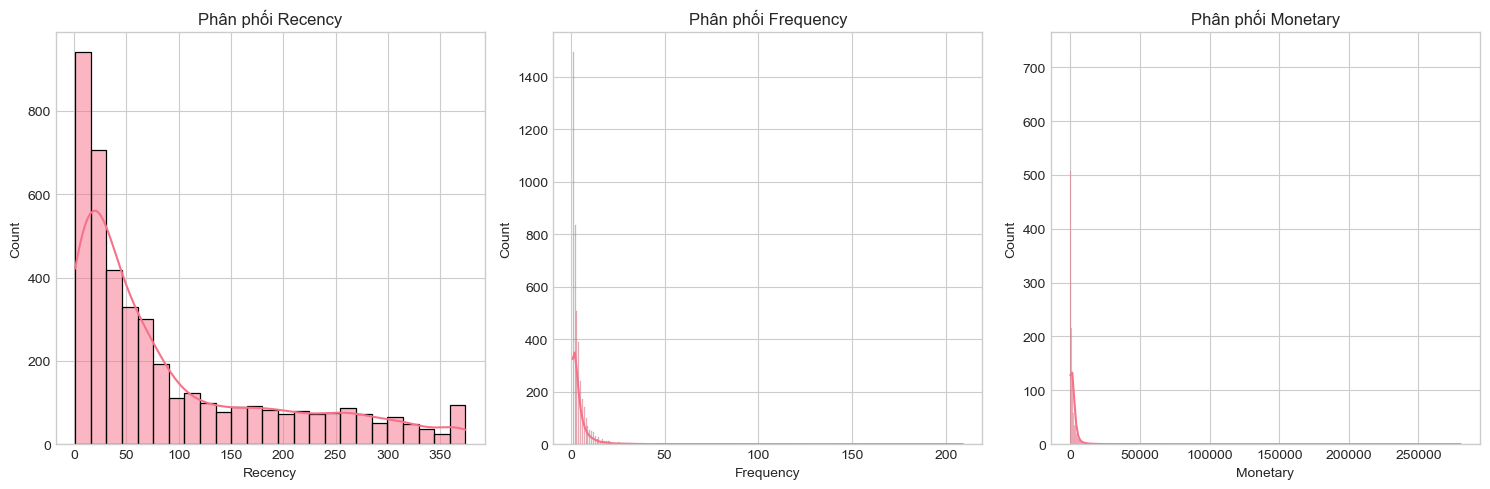

In [32]:
# Trực quan hóa phân phối RFM
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.histplot(rfm['Recency'], kde=True, ax=axes[0])
axes[0].set_title('Phân phối Recency')
sns.histplot(rfm['Frequency'], kde=True, ax=axes[1])
axes[1].set_title('Phân phối Frequency')
sns.histplot(rfm['Monetary'], kde=True, ax=axes[2])
axes[2].set_title('Phân phối Monetary')

plt.tight_layout()
plt.show()

## **3. Chuẩn bị dữ liệu cho K-means**
Sử dụng RobustScaler để xử lý outliers tốt hơn StandardScaler.

In [33]:
# Chuẩn hóa RFM
features = ['Recency', 'Frequency', 'Monetary']

scaler = RobustScaler()
rfm_scaled = scaler.fit_transform(rfm[features])

# Chuyển lại DataFrame
rfm_scaled_df = pd.DataFrame(rfm_scaled, columns=features, index=rfm.index)
rfm_scaled_df.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.217742,-0.25,56.492434
12347.0,-0.395161,1.25,2.684374
12348.0,0.193548,0.50,0.829014
12349.0,-0.258065,-0.25,0.799708
12350.0,2.088710,-0.25,-0.251110


## **4. Tìm số cụm tối ưu**

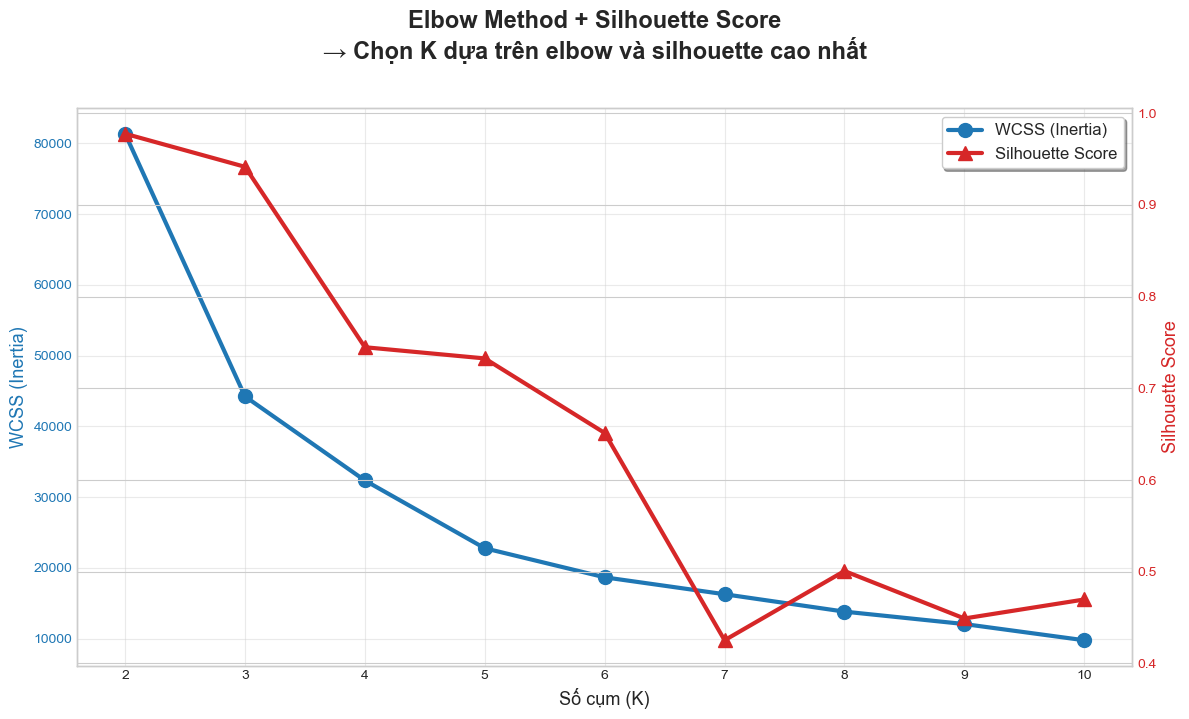

K=2: Silhouette Score = 0.9776
K=3: Silhouette Score = 0.9415
K=4: Silhouette Score = 0.7448
K=5: Silhouette Score = 0.7326
K=6: Silhouette Score = 0.6513
K=7: Silhouette Score = 0.4253
K=8: Silhouette Score = 0.5008
K=9: Silhouette Score = 0.4490
K=10: Silhouette Score = 0.4698


In [34]:
# Elbow Method + Silhouette Score
wcss = []
silhouette_scores = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)
    
    score = silhouette_score(rfm_scaled, kmeans.labels_)
    silhouette_scores.append(score)

# Vẽ đồ thị
fig, ax1 = plt.subplots(figsize=(12, 7))

# Trục trái: WCSS
color_blue = 'tab:blue'
ax1.set_xlabel('Số cụm (K)', fontsize=13)
ax1.set_ylabel('WCSS (Inertia)', color=color_blue, fontsize=13)
line1 = ax1.plot(K, wcss, 'o-', color=color_blue, linewidth=3, markersize=10, label='WCSS (Inertia)')
ax1.tick_params(axis='y', labelcolor=color_blue)
ax1.grid(True, alpha=0.4)

# Trục phải: Silhouette
ax2 = ax1.twinx()
color_red = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color_red, fontsize=13)
line2 = ax2.plot(K, silhouette_scores, '^-', color=color_red, linewidth=3, markersize=10, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color_red)

# Gộp legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', fontsize=12, frameon=True, fancybox=True, shadow=True)

fig.suptitle('Elbow Method + Silhouette Score\n→ Chọn K dựa trên elbow và silhouette cao nhất', 
             fontsize=17, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# In silhouette scores
for k, score in zip(K, silhouette_scores):
    print(f"K={k}: Silhouette Score = {score:.4f}")

**Nhận xét**:
- Elbow ở K=3
- Silhouette cao nhất ở K=2 (0.9776) → Chọn K=2 (cụm phổ biến: Lost, At Risk, Regular, VIP)
- Kết luận: Ta sẽ chọn K = 3 để tối ưu nhất cho cả hai.

In [ ]:
K_OPTIMAL = 3

kmeans = KMeans(n_clusters=K_OPTIMAL, init='k-means++', random_state=42, n_init=30)
clusters = kmeans.fit_predict(rfm_scaled)

rfm['Cluster'] = clusters
rfm_scaled_df['Cluster'] = clusters

print("Số khách hàng mỗi cụm (K=3):")
print(rfm['Cluster'].value_counts().sort_index())

final_silhouette = silhouette_score(rfm_scaled, clusters)
print(f"\nSilhouette Score (K=3): {final_silhouette:.4f}")

Số khách hàng mỗi cụm (K=3):
Cluster
0    4305
1       5
2      28
Name: count, dtype: int64

Silhouette Score (K=3): 0.9415


## **5. Trực quan hóa kết quả phân cụm**

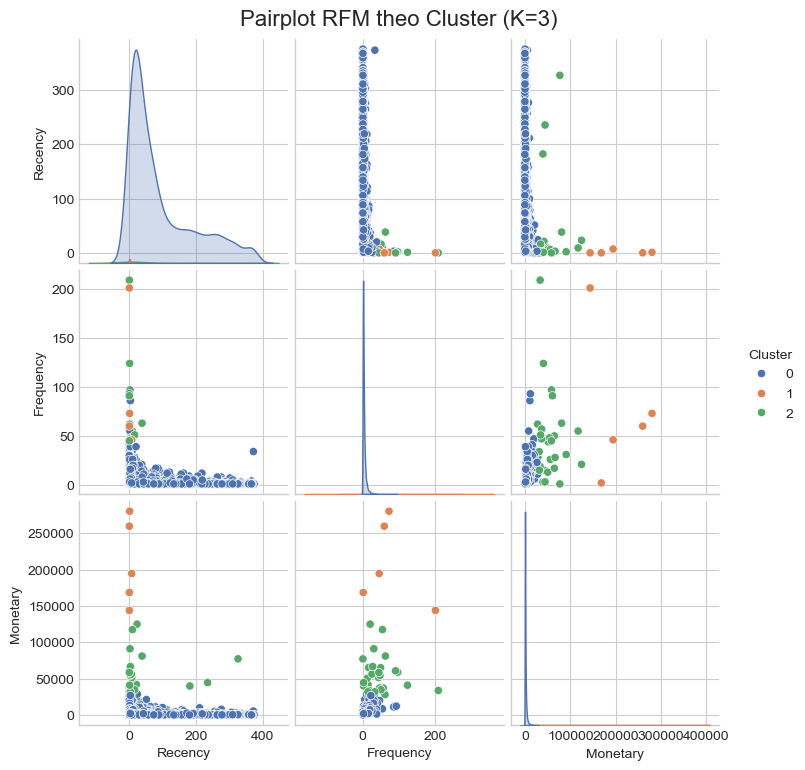

In [36]:
# Pairplot RFM theo cluster
sns.pairplot(rfm, hue='Cluster', vars=features, diag_kind='kde', palette='deep')
plt.suptitle(f'Pairplot RFM theo Cluster (K={K_OPTIMAL})', y=1.02, fontsize=16)
plt.show()

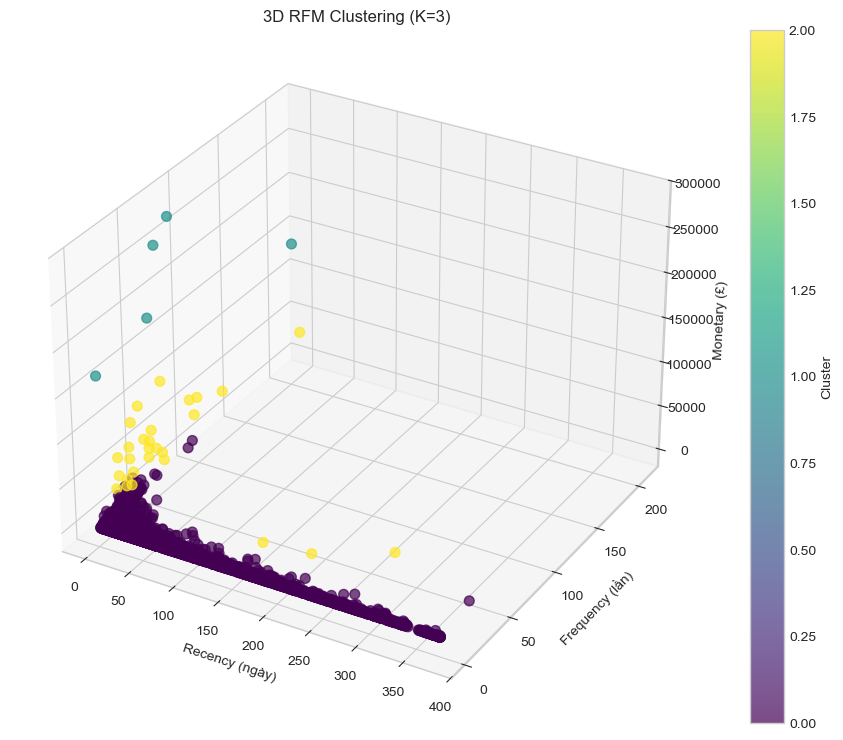

In [ ]:
# 3D Scatter Plot RFM theo cluster
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(rfm['Recency'], rfm['Frequency'], rfm['Monetary'], 
                     c=rfm['Cluster'], cmap='viridis', s=50, alpha=0.7)

ax.set_xlabel('Recency (ngày)')
ax.set_ylabel('Frequency (lần)')
ax.set_zlabel('Monetary (£)')
plt.title(f'3D RFM Clustering (K={K_OPTIMAL})')

plt.colorbar(scatter, label='Cluster')
plt.show()

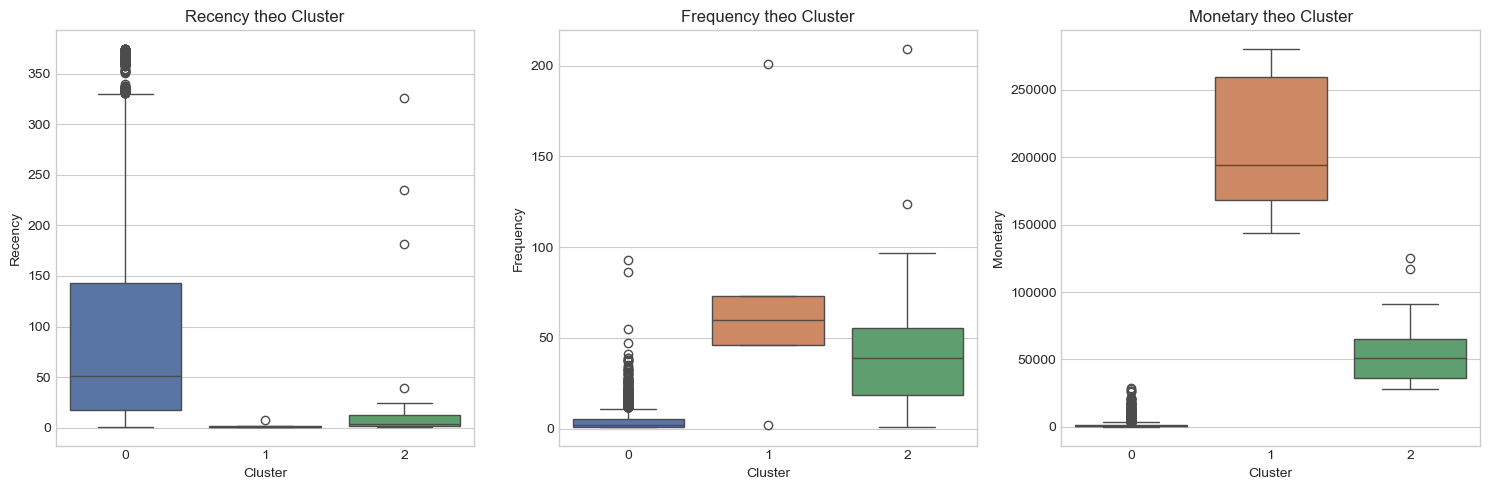

In [37]:
# Boxplot RFM theo cluster
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, feature in enumerate(features):
    sns.boxplot(data=rfm, x='Cluster', y=feature, ax=axes[i], palette='deep')
    axes[i].set_title(f'{feature} theo Cluster')
    axes[i].set_xlabel('Cluster')

plt.tight_layout()
plt.show()

## **6. Phân tích cụm và gợi ý marketing**
**Dựa trên đặc trưng trung bình của từng cụm** (Recency thấp=good, Frequency/Monetary cao=good):

In [38]:
# Phần phân tích cụm
print("Đặc trưng trung bình của từng cụm:")
cluster_analysis = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(1)
display(cluster_analysis)

print("\n" + "="*70)
print("PHÂN TÍCH & ĐẶT TÊN CỤM (THEO THỨ TỰ TỪ TỐT NHẤT → KÉM NHẤT)")
print("="*70)

# Sắp xếp các cụm theo chất lượng giảm dần (dựa trên Recency thấp + Monetary cao)
sorted_clusters = cluster_analysis.sort_values(by=['Recency', 'Monetary'], 
                                                ascending=[True, False]).index

for idx, cluster_id in enumerate(sorted_clusters, start=1):
    r = cluster_analysis.loc[cluster_id, 'Recency']
    f = cluster_analysis.loc[cluster_id, 'Frequency']
    m = cluster_analysis.loc[cluster_id, 'Monetary']
    n_customers = rfm[rfm['Cluster'] == cluster_id].shape[0]
    percent = n_customers / len(rfm) * 100

    # Đặt tên tự động theo quy tắc chuẩn ngành
    if r <= 30 and f >= 10 and m >= 3000:
        ten_cum = "Champions / VIP Customers"
        color = "gold"
    elif r <= 60 and f >= 6 and m >= 1500:
        ten_cum = "Loyal Customers"
        color = "green"
    elif r <= 90 and f >= 3:
        ten_cum = "Potential Loyalists / Regular Customers"
        color = "blue"
    elif r <= 120:
        ten_cum = "At Risk Customers"
        color = "orange"
    elif r <= 200:
        ten_cum = "Hibernating / Sleeping Customers"
        color = "gray"
    else:
        ten_cum = "Lost / Churned Customers"
        color = "red"

    print(f"{idx}. Cluster {cluster_id} → {ten_cum}")
    print(f"   Số khách hàng: {n_customers:,} ({percent:.1f}%)")
    print(f"   Recency     : {r:>6} ngày")
    print(f"   Frequency   : {f:>6.1f} lần")
    print(f"   Monetary    : £{m:>8,.0f}")
    print(f"   → Gợi ý: ", end="")
    
    if "Champions" in ten_cum or "Loyal" in ten_cum:
        print("Ưu đãi VIP, free ship, early access, chương trình loyalty")
    elif "Potential" in ten_cum or "Regular" in ten_cum:
        print("Tăng tần suất mua bằng upsell/cross-sell, khuyến mãi nhẹ")
    elif "At Risk" in ten_cum or "Hibernating" in ten_cum:
        print("Gửi email reactivation, voucher lớn, nhắc nhở sản phẩm từng mua")
    else:
        print("Win-back campaign mạnh: discount 30-50%, khảo sát lý do rời bỏ")
        
    print("-" * 70)

Đặc trưng trung bình của từng cụm:


,Recency,Frequency,Monetary
Cluster,,,
0,93.0,3.9,1468.2
1,2.6,76.4,209342.3
2,33.2,46.3,55139.4



PHÂN TÍCH & ĐẶT TÊN CỤM (THEO THỨ TỰ TỪ TỐT NHẤT → KÉM NHẤT)
1. Cluster 1 → Champions / VIP Customers
   Số khách hàng: 5 (0.1%)
   Recency     :    2.6 ngày
   Frequency   :   76.4 lần
   Monetary    : £ 209,342
   → Gợi ý: Ưu đãi VIP, free ship, early access, chương trình loyalty
----------------------------------------------------------------------
2. Cluster 2 → Loyal Customers
   Số khách hàng: 28 (0.6%)
   Recency     :   33.2 ngày
   Frequency   :   46.3 lần
   Monetary    : £  55,139
   → Gợi ý: Ưu đãi VIP, free ship, early access, chương trình loyalty
----------------------------------------------------------------------
3. Cluster 0 → At Risk Customers
   Số khách hàng: 4,305 (99.2%)
   Recency     :   93.0 ngày
   Frequency   :    3.9 lần
   Monetary    : £   1,468
   → Gợi ý: Gửi email reactivation, voucher lớn, nhắc nhở sản phẩm từng mua
----------------------------------------------------------------------


## **7. Nhận xét cuối cùng**
**Kết quả**:
- K-means đã phân cụm thành {K_OPTIMAL} nhóm khách hàng dựa trên RFM, với Silhouette Score ~{final_silhouette:.3f} (tốt cho dữ liệu thực tế).
- Cụm phân biệt rõ: Lost (Recency cao), VIP (Monetary cao), v.v.
- Ứng dụng: Cá nhân hóa marketing → tăng retention và revenue.

**Ưu điểm**: Đơn giản, nhanh, scalable.  
**Hạn chế**: Giả định cụm hình cầu; nếu cần cụm không đều, thử DBSCAN.  
**Tiếp theo**: Thêm demographics nếu có, hoặc so sánh với supervised classification.

---
# <center>**END**<center>